# Lab 04 - Text Preprocessing and Edit Distance

**Name:** Zain Ul Wahaj
**Roll Number:** FA23-BAI-058
**Course:** Natural Language Processing

---

This notebook contains the complete solution to all **9 tasks** of Lab 04.
Each part is solved in its own code cell, directly below the question it answers,
with its output shown underneath.

Libraries: `re`, `nltk`, `spacy` (`en_core_web_sm`), `pandas`, `matplotlib`, `scikit-learn` and `requests` (only for the translation step in Task 04).

### Contents

1. **Task 01** - Lowercasing Basics and Its Drawbacks
2. **Task 02** - Noise Removal Pipeline
3. **Task 03** - Stop-Word Removal and Its Effect on Vocabulary
4. **Task 04** - Risks of Stop-Word Removal (Sentiment, MT, Chatbots)
5. **Task 05** - Hands-On with the Porter Stemmer
6. **Task 06** - Lemmatization (spaCy) vs. Stemming
7. **Task 07** - Preprocessing Pipeline
8. **Task 08** - Implementing Minimum Edit Distance (Levenshtein)
9. **Task 09** - Spelling Correction with Edit Distance

In [1]:
# Zain Ul Wahaj | FA23-BAI-058
# Natural Language Processing - Lab 04 - Text Preprocessing and Edit Distance

NAME = "Zain Ul Wahaj"
ROLL_NUMBER = "FA23-BAI-058"

print("Name        :", NAME)
print("Roll Number :", ROLL_NUMBER)
print("Course      :", "Natural Language Processing")
print("Lab         :", "Lab 04 - Text Preprocessing and Edit Distance")

import re
import time
import string
import collections
import textwrap

import nltk
import spacy
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.dpi"] = 80

# NLTK data packages used in this lab. Each one is downloaded only if it is missing.
for path, package in [("tokenizers/punkt_tab", "punkt_tab"), ("corpora/stopwords", "stopwords"),
                      ("corpora/movie_reviews", "movie_reviews"), ("corpora/brown", "brown")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(package, quiet=True)

nlp = spacy.load("en_core_web_sm")

print("\nnltk  :", nltk.__version__)
print("spaCy :", spacy.__version__, "| model:", nlp.meta["lang"] + "_" + nlp.meta["name"], nlp.meta["version"])

Name        : Zain Ul Wahaj
Roll Number : FA23-BAI-058
Course      : Natural Language Processing
Lab         : Lab 04 - Text Preprocessing and Edit Distance



nltk  : 3.10.3
spaCy : 3.8.16 | model: en_core_web_sm 3.8.0


---

## Task 01: Lowercasing Basics and Its Drawbacks

**Topic:** Case normalization: what it simplifies and what it breaks

### Task 01 (1)

> Build a small corpus of at least 10 sentences containing mixed-case words (e.g., "Apple", "apple", "APPLE", "US", "us").

In [2]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (1)
corpus = [
    "Apple released a new phone, and I ate an apple while reading about it.",
    "APPLE shares rose today, but the apple pie was cheaper.",
    "The US government asked us to share our data.",
    "Please tell us what the US team found.",
    "Bill paid the bill before the March deadline.",
    "We will march to the square in March.",
    "Turkey is famous for its food, and we cooked a turkey for dinner.",
    "Polish is hard to learn, so please polish your notes.",
    "Mark will mark the exam papers tomorrow.",
    "I use Windows at work and open the windows at home.",
    "She works at Amazon and loves the Amazon river.",
    "Java is a programming language, but I prefer a cup of java.",
]

print("Sentences in the corpus:", len(corpus))
for i, s in enumerate(corpus, 1):
    print(f"{i:>2}. {s}")

Sentences in the corpus: 12
 1. Apple released a new phone, and I ate an apple while reading about it.
 2. APPLE shares rose today, but the apple pie was cheaper.
 3. The US government asked us to share our data.
 4. Please tell us what the US team found.
 5. Bill paid the bill before the March deadline.
 6. We will march to the square in March.
 7. Turkey is famous for its food, and we cooked a turkey for dinner.
 8. Polish is hard to learn, so please polish your notes.
 9. Mark will mark the exam papers tomorrow.
10. I use Windows at work and open the windows at home.
11. She works at Amazon and loves the Amazon river.
12. Java is a programming language, but I prefer a cup of java.


### Task 01 (2)

> Lowercase the corpus and compare the vocabulary size before and after.

In [3]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (2)
def tokens_of(text):
    return re.findall(r"[A-Za-z]+", text)           # words only, no punctuation


vocab_before = set(tok for s in corpus for tok in tokens_of(s))
vocab_after = set(tok for s in corpus for tok in tokens_of(s.lower()))

print("Vocabulary size before lowercasing:", len(vocab_before))
print("Vocabulary size after lowercasing :", len(vocab_after))
print("Types merged                      :", len(vocab_before) - len(vocab_after))

# Which different spellings collapsed into one word?
groups = collections.defaultdict(set)
for tok in vocab_before:
    groups[tok.lower()].add(tok)
merged = {k: sorted(v) for k, v in groups.items() if len(v) > 1}
print("\nWords that were merged:")
for lower, forms in sorted(merged.items()):
    print(f"   {lower:<8} <- {forms}")

Vocabulary size before lowercasing: 90
Vocabulary size after lowercasing : 77
Types merged                      : 13

Words that were merged:
   apple    <- ['APPLE', 'Apple', 'apple']
   bill     <- ['Bill', 'bill']
   java     <- ['Java', 'java']
   march    <- ['March', 'march']
   mark     <- ['Mark', 'mark']
   please   <- ['Please', 'please']
   polish   <- ['Polish', 'polish']
   the      <- ['The', 'the']
   turkey   <- ['Turkey', 'turkey']
   us       <- ['US', 'us']
   we       <- ['We', 'we']
   windows  <- ['Windows', 'windows']


### Task 01 (3)

> Find 3 examples where lowercasing makes the meaning ambiguous (e.g., "US" vs. "us", "Apple" the company vs. the fruit).

In [4]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (3)
examples = [
    ("US / us",      "US = the United States, us = the pronoun 'we'",
     "The US government asked us to share our data."),
    ("Apple / apple", "Apple = the company, apple = the fruit",
     "Apple released a new phone, and I ate an apple while reading about it."),
    ("Bill / bill",  "Bill = a person's name, bill = an invoice",
     "Bill paid the bill before the March deadline."),
    ("March / march", "March = the month, march = to walk in a group",
     "We will march to the square in March."),
]

for word, meanings, sentence in examples:
    print(f"{word}\n   meanings : {meanings}")
    print(f"   original : {sentence}")
    print(f"   lowercase: {sentence.lower()}\n")

# Check with code that each pair really becomes ONE vocabulary entry after lowercasing
for pair in ["US", "Apple", "Bill", "March"]:
    print(f"{pair!r} and {pair.lower()!r} both present before lowercasing:",
          pair in vocab_before and pair.lower() in vocab_before,
          "-> one type after:", pair.lower() in vocab_after)

US / us
   meanings : US = the United States, us = the pronoun 'we'
   original : The US government asked us to share our data.
   lowercase: the us government asked us to share our data.

Apple / apple
   meanings : Apple = the company, apple = the fruit
   original : Apple released a new phone, and I ate an apple while reading about it.
   lowercase: apple released a new phone, and i ate an apple while reading about it.

Bill / bill
   meanings : Bill = a person's name, bill = an invoice
   original : Bill paid the bill before the March deadline.
   lowercase: bill paid the bill before the march deadline.

March / march
   meanings : March = the month, march = to walk in a group
   original : We will march to the square in March.
   lowercase: we will march to the square in march.

'US' and 'us' both present before lowercasing: True -> one type after: True
'Apple' and 'apple' both present before lowercasing: True -> one type after: True
'Bill' and 'bill' both present before lowercasi

### Task 01 (4)

> Write a short paragraph explaining which NLP tasks (NER, sentiment analysis, search) can be harmed by lowercasing, and why.

In [5]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (4)
paragraph = (
    "Lowercasing is cheap and it shrinks the vocabulary, but it throws away information that some tasks need. "
    "Named entity recognition is hurt the most: a capital letter is one of the strongest clues that a word is a name, "
    "so 'Apple', 'Bill' and 'Turkey' look just like the common nouns 'apple', 'bill' and 'turkey' and the model can "
    "no longer tell a company from a fruit or a person from an invoice. Sentiment analysis is hurt in a smaller way: "
    "'GREAT' written in capitals carries more emphasis than 'great', and that intensity is lost, although most of the "
    "sentiment words survive. Search is the task that usually benefits, because a user who types 'apple' also wants "
    "pages that say 'Apple' at the start of a sentence, but it can still return the wrong sense of an ambiguous word "
    "such as 'US' versus 'us'."
)
print(textwrap.fill(paragraph, width=100))

Lowercasing is cheap and it shrinks the vocabulary, but it throws away information that some tasks
need. Named entity recognition is hurt the most: a capital letter is one of the strongest clues that
a word is a name, so 'Apple', 'Bill' and 'Turkey' look just like the common nouns 'apple', 'bill'
and 'turkey' and the model can no longer tell a company from a fruit or a person from an invoice.
Sentiment analysis is hurt in a smaller way: 'GREAT' written in capitals carries more emphasis than
'great', and that intensity is lost, although most of the sentiment words survive. Search is the
task that usually benefits, because a user who types 'apple' also wants pages that say 'Apple' at
the start of a sentence, but it can still return the wrong sense of an ambiguous word such as 'US'
versus 'us'.


---

## Task 02: Noise Removal Pipeline

**Topic:** Cleaning noisy social-media text with regular expressions

### Task 02 (1)

> Create or download a "noisy" dataset of tweets or reviews (at least 15 entries) containing URLs, @mentions, #hashtags, emojis, HTML tags and extra whitespace.

In [6]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (1)
noisy_tweets = [
    "OMG!!! Just got the new iPhone 15 😍😍 https://t.co/aB3dE9 #Apple #iPhone @TechGuru check this out",
    "<p>Loved the movie!!!   Best film of 2023 :) <br/> 10/10 would watch again</p>",
    "@john_doe Thanks for the help!!  visit https://www.example.com/help?id=42&ref=tw for more   details",
    "I'm learning C++ and Python this semester #coding #CS101 <b>so</b> much fun 🙌",
    "Paid $100 for this phone... totally worth it!!! @StoreOfficial http://bit.ly/3xYz",
    "<div class='review'>Great    service, but the food was cold :(</div>   ",
    "5G is finally here in the U.S.!!!  #5G #tech https://news.example.org/5g-launch",
    "RT @newsdaily: Breaking: Prices up by 50% this week 📈 #economy",
    "This e-mail   is spam <a href='http://spam.example'>click here</a> to win $1000000 😂😂😂",
    "Can't believe it's already 2024... time flies ⏰ #newyear @friend1 @friend2",
    "Terrible customer care!! Waited 3 hours...   no reply from @SupportTeam 😡 #fail",
    "<h1>Review</h1><p>Battery life is 8hrs & the screen is 6.5\" - not bad!</p>",
    "Good morning everyone ☀️ Coffee ☕ + code = happy day #developer https://t.co/xx12",
    "Check my blog: www.mynotes.blog/nlp-tips   (it's free!!!) #NLP #AI",
    "LOL that was so funny 😂😂 @Sara_K you have to see this https://youtu.be/dQw4w9WgXcQ",
    "Ordered 2 pizzas for Rs. 1500 - delivery took 90 min    😤 #disappointed",
    "<3 this song!!! Streaming on https://music.example.com/track/99 #nowplaying",
    "Wow...   @elonmusk's new post got 12.5K likes 👍 #X #viral http://t.co/zz9",
]

print("Entries in the dataset:", len(noisy_tweets))
print("Noise types present   : URLs, @mentions, #hashtags, emojis, HTML tags, extra whitespace\n")
for i, t in enumerate(noisy_tweets[:5], 1):
    print(f"{i}. {t!r}")
print("   ...")

Entries in the dataset: 18
Noise types present   : URLs, @mentions, #hashtags, emojis, HTML tags, extra whitespace

1. 'OMG!!! Just got the new iPhone 15 😍😍 https://t.co/aB3dE9 #Apple #iPhone @TechGuru check this out'
2. '<p>Loved the movie!!!   Best film of 2023 :) <br/> 10/10 would watch again</p>'
3. '@john_doe Thanks for the help!!  visit https://www.example.com/help?id=42&ref=tw for more   details'
4. "I'm learning C++ and Python this semester #coding #CS101 <b>so</b> much fun 🙌"
5. 'Paid $100 for this phone... totally worth it!!! @StoreOfficial http://bit.ly/3xYz'
   ...


### Task 02 (2)

> Write a separate regex function for each noise type (URL removal, HTML tag removal, mention/hashtag handling, punctuation and extra-whitespace removal).

In [7]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (2)
def remove_urls(text):
    """http://..., https://... and www.... up to the next space."""
    return re.sub(r"(?:https?://|www\.)\S+", " ", text)


def remove_html(text):
    """Anything between < and >, such as <p>, </div>, <br/> or <a href='...'>."""
    return re.sub(r"<[^>]+>", " ", text)


def remove_mentions(text):
    """@username is removed completely: it names a person, not content."""
    return re.sub(r"@\w+", " ", text)


def handle_hashtags(text):
    """#word is kept as the plain word, because the topic word itself is useful."""
    return re.sub(r"#(\w+)", r"\1", text)


def remove_emojis(text):
    """Emoji and pictograph code point ranges, plus the invisible variation selector."""
    return re.sub("[\U0001F300-\U0001FAFF☀-➿⬀-⯿⏩-⏿️]+", " ", text)


def remove_punctuation(text):
    """Every character that is not a letter, digit, underscore or whitespace."""
    return re.sub(r"[^\w\s]", " ", text)


def normalize_whitespace(text):
    """Collapse runs of spaces, tabs and newlines into one space and trim the ends."""
    return re.sub(r"\s+", " ", text).strip()


sample = noisy_tweets[0]
print("original :", repr(sample))
for fn in (remove_urls, remove_mentions, handle_hashtags, remove_emojis, remove_punctuation, normalize_whitespace):
    sample = fn(sample)
    print(f"{fn.__name__:<20}->", repr(sample))

original : 'OMG!!! Just got the new iPhone 15 😍😍 https://t.co/aB3dE9 #Apple #iPhone @TechGuru check this out'
remove_urls         -> 'OMG!!! Just got the new iPhone 15 😍😍   #Apple #iPhone @TechGuru check this out'
remove_mentions     -> 'OMG!!! Just got the new iPhone 15 😍😍   #Apple #iPhone   check this out'
handle_hashtags     -> 'OMG!!! Just got the new iPhone 15 😍😍   Apple iPhone   check this out'
remove_emojis       -> 'OMG!!! Just got the new iPhone 15     Apple iPhone   check this out'
remove_punctuation  -> 'OMG    Just got the new iPhone 15     Apple iPhone   check this out'
normalize_whitespace-> 'OMG Just got the new iPhone 15 Apple iPhone check this out'


### Task 02 (3)

> Combine these into a single clean_text() pipeline and examine the effect of ordering. Does changing the order of steps change the output?

In [8]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (3)
STEPS = {
    "html": remove_html, "urls": remove_urls, "mentions": remove_mentions,
    "hashtags": handle_hashtags, "emojis": remove_emojis,
    "punct": remove_punctuation, "spaces": normalize_whitespace,
}

GOOD_ORDER = ["html", "urls", "mentions", "hashtags", "emojis", "punct", "spaces"]
BAD_ORDER = ["punct", "html", "urls", "mentions", "hashtags", "emojis", "spaces"]    # punctuation first


def clean_text(text, order=GOOD_ORDER):
    """Run the cleaning steps in the given order."""
    for name in order:
        text = STEPS[name](text)
    return text


cleaned_good = [clean_text(t, GOOD_ORDER) for t in noisy_tweets]
cleaned_bad = [clean_text(t, BAD_ORDER) for t in noisy_tweets]

different = [i for i in range(len(noisy_tweets)) if cleaned_good[i] != cleaned_bad[i]]
print(f"Tweets where the order changes the output: {len(different)} of {len(noisy_tweets)}\n")

for i in different[:4]:
    print("original        :", repr(noisy_tweets[i]))
    print("good order      :", repr(cleaned_good[i]))
    print("punctuation 1st :", repr(cleaned_bad[i]), "\n")

print("Yes, the order matters. If punctuation is removed first, the characters that make a URL, an HTML tag")
print("or an @mention recognisable (:, /, <, >, @) are already gone, so pieces such as 'https', 'www', 'br'")
print("and 'p' are left in the text. URLs, HTML and mentions must be removed before punctuation.")

Tweets where the order changes the output: 17 of 18

original        : 'OMG!!! Just got the new iPhone 15 😍😍 https://t.co/aB3dE9 #Apple #iPhone @TechGuru check this out'
good order      : 'OMG Just got the new iPhone 15 Apple iPhone check this out'
punctuation 1st : 'OMG Just got the new iPhone 15 https t co aB3dE9 Apple iPhone TechGuru check this out' 

original        : '<p>Loved the movie!!!   Best film of 2023 :) <br/> 10/10 would watch again</p>'
good order      : 'Loved the movie Best film of 2023 10 10 would watch again'
punctuation 1st : 'p Loved the movie Best film of 2023 br 10 10 would watch again p' 

original        : '@john_doe Thanks for the help!!  visit https://www.example.com/help?id=42&ref=tw for more   details'
good order      : 'Thanks for the help visit for more details'
punctuation 1st : 'john_doe Thanks for the help visit https www example com help id 42 ref tw for more details' 

original        : "I'm learning C++ and Python this semester #coding #CS101 <b>so<

### Task 02 (4)

> Make a table of 5 examples before and after cleaning, and point out where cleaning went too far (over-cleaning), such as damaging "C++" or "$100".

In [9]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (4)
picked = [3, 4, 6, 7, 11]            # tweets that contain C++, $100, 5G / U.S., 50% and 6.5"

for i in picked:
    print(f"[{i}] BEFORE: {noisy_tweets[i]!r}")
    print(f"    AFTER : {cleaned_good[i]!r}\n")

# Over-cleaning check: meaningful terms that exist in the original but not in the cleaned text
important = ["C++", "$100", "5G", "U.S.", "50%", '6.5"', "e-mail", "12.5K", "Rs. 1500", "10/10", "$1000000", "can't"]
print("Meaningful terms damaged by cleaning:")
for term in important:
    for before, after in zip(noisy_tweets, cleaned_good):
        if term in before and term not in after:
            print(f"   {term:<10} -> in '{before[:40]}...' it became: '{after[:40]}...'")
            break

print("\nOVER-CLEANING: the punctuation step deletes characters that carry meaning.")
print("   C++      -> 'C'        a different programming language")
print("   $100     -> '100'      the currency is lost, so it is no longer clear that this is a price")
print("   50%      -> '50'       a percentage turns into a plain number")
print("   U.S.     -> 'U S'      one abbreviation is split into two letters")
print("   6.5 / 12.5K -> '6 5' / '12 5K'  a decimal number becomes two separate numbers")
print("   e-mail / 10/10 -> 'e mail' / '10 10'  one word or one rating becomes two tokens")
print("A safer pipeline keeps $, %, +, ., - and / when they sit inside a token, and removes only stray punctuation.")

[3] BEFORE: "I'm learning C++ and Python this semester #coding #CS101 <b>so</b> much fun 🙌"
    AFTER : 'I m learning C and Python this semester coding CS101 so much fun'

[4] BEFORE: 'Paid $100 for this phone... totally worth it!!! @StoreOfficial http://bit.ly/3xYz'
    AFTER : 'Paid 100 for this phone totally worth it'

[6] BEFORE: '5G is finally here in the U.S.!!!  #5G #tech https://news.example.org/5g-launch'
    AFTER : '5G is finally here in the U S 5G tech'

[7] BEFORE: 'RT @newsdaily: Breaking: Prices up by 50% this week 📈 #economy'
    AFTER : 'RT Breaking Prices up by 50 this week economy'

[11] BEFORE: '<h1>Review</h1><p>Battery life is 8hrs & the screen is 6.5" - not bad!</p>'
    AFTER : 'Review Battery life is 8hrs the screen is 6 5 not bad'

Meaningful terms damaged by cleaning:
   C++        -> in 'I'm learning C++ and Python this semeste...' it became: 'I m learning C and Python this semester ...'
   $100       -> in 'Paid $100 for this phone... totally wort...' it be

---

## Task 03: Stop-Word Removal and Its Effect on Vocabulary

**Topic:** What stop-word removal does to a text collection

### Task 03 (1)

> Load NLTK's English stop-word list, print the first 20 words, and report the list's total size.

In [10]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (1)
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))
as_list = stopwords.words("english")

print("First 20 stop words:", as_list[:20])
print("Total size of the list:", len(as_list))
print("\nSome words you might not expect in it:", [w for w in ("not", "no", "nor", "very", "against", "don") if w in stop_words])

First 20 stop words: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
Total size of the list: 198

Some words you might not expect in it: ['not', 'no', 'nor', 'very', 'against', 'don']


### Task 03 (2)

> Apply stop-word removal to a dataset (movie reviews or news) and compare token count, vocabulary size and average sentence length before and after.

In [11]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (2)
from nltk.corpus import movie_reviews

# Dataset: NLTK movie_reviews (2000 reviews). Every sentence is a list of tokens already.
sentences = [[w.lower() for w in sent if w.isalpha()] for sent in movie_reviews.sents()]
sentences = [s for s in sentences if s]                       # drop sentences with no words at all
sentences_no_stop = [[w for w in s if w not in stop_words] for s in sentences]
sentences_no_stop = [s for s in sentences_no_stop if s]       # a sentence of only stop words disappears


def stats(sents):
    tokens = [w for s in sents for w in s]
    return len(tokens), len(set(tokens)), len(tokens) / len(sents)


rows = []
for name, sents in [("before", sentences), ("after", sentences_no_stop)]:
    t, v, a = stats(sents)
    rows.append((name, len(sents), t, v, a))

print(f"{'':<8}{'sentences':>11}{'tokens':>10}{'vocabulary':>12}{'avg sent. length':>18}")
for name, n, t, v, a in rows:
    print(f"{name:<8}{n:>11}{t:>10}{v:>12}{a:>18.2f}")

before, after = rows[0], rows[1]
print(f"\nTokens removed       : {(1 - after[2] / before[2]) * 100:.1f}%")
print(f"Vocabulary removed   : {(1 - after[3] / before[3]) * 100:.2f}%  (only the {before[3] - after[3]} stop words themselves)")
print(f"Avg sentence length  : {before[4]:.2f} -> {after[4]:.2f}")

          sentences    tokens  vocabulary  avg sent. length
before        67676   1329753       38889             19.65
after         67033    701543       38738             10.47

Tokens removed       : 47.2%
Vocabulary removed   : 0.39%  (only the 151 stop words themselves)
Avg sentence length  : 19.65 -> 10.47


### Task 03 (3)

> Plot bar charts of the top-15 most frequent words before and after removal.

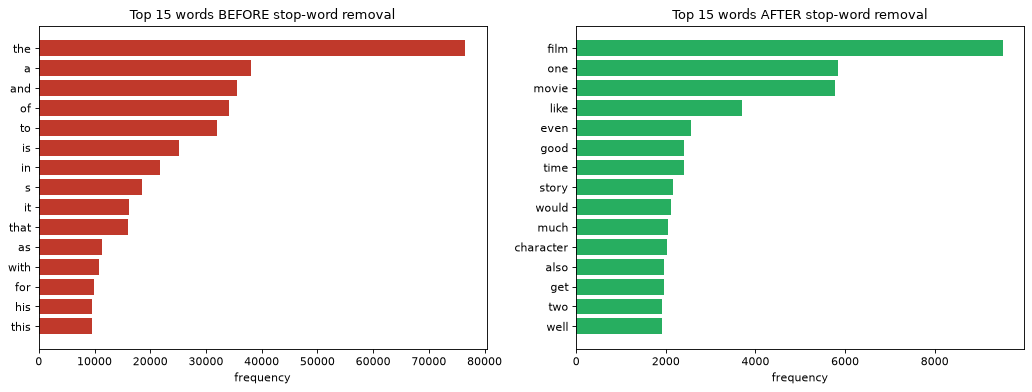

Before: ['the', 'a', 'and', 'of', 'to', 'is', 'in', 's'] ...
After : ['film', 'one', 'movie', 'like', 'even', 'good', 'time', 'story'] ...


In [12]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (3)
count_before = collections.Counter(w for s in sentences for w in s)
count_after = collections.Counter(w for s in sentences_no_stop for w in s)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, counter, title, colour in [(axes[0], count_before, "Top 15 words BEFORE stop-word removal", "#c0392b"),
                                   (axes[1], count_after, "Top 15 words AFTER stop-word removal", "#27ae60")]:
    words, counts = zip(*counter.most_common(15))
    ax.barh(words[::-1], counts[::-1], color=colour)
    ax.set_title(title)
    ax.set_xlabel("frequency")
plt.tight_layout()
plt.show()

print("Before:", [w for w, _ in count_before.most_common(8)], "...")
print("After :", [w for w, _ in count_after.most_common(8)], "...")

### Task 03 (4)

> Create your own custom stop-word list by adding or removing at least 10 domain-specific words, and justify each choice.

In [13]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (4)
# Domain: movie reviews.
add_words = {
    "film":   "appears in almost every review, so it does not help tell reviews apart",
    "films":  "plural of 'film', same reason",
    "movie":  "same as 'film'; the domain word itself carries no opinion",
    "movies": "plural of 'movie', same reason",
    "one":    "very common filler ('one of the best', 'no one') with no topic information",
    "also":   "linking word that adds no meaning",
    "even":   "linking word that adds no meaning",
    "would":  "modal verb that is extremely frequent in reviews and not informative",
    "could":  "modal verb, same reason as 'would'",
    "get":    "generic verb ('get to', 'get out') that tells us nothing about the film",
}
remove_words = {
    "not":     "negation: 'not good' is the opposite of 'good'",
    "no":      "negation: 'no plot' is a complaint",
    "nor":     "negation word",
    "very":    "intensifier: 'very good' is stronger than 'good'",
    "too":     "'too long' and 'too slow' are complaints",
    "against": "marks opposition ('against the odds')",
    "few":     "quantity that changes meaning ('few laughs')",
    "most":    "'most boring' carries a strong opinion",
    "but":     "contrast word: 'good but boring' flips the opinion",
    "don":     "left over from splitting \"don't\"; negation",
}

custom_stop = (stop_words | set(add_words)) - set(remove_words)
print(f"Built-in list : {len(stop_words)} words")
print(f"Added         : {len(add_words)} words")
print(f"Removed       : {len(remove_words)} words")
print(f"Custom list   : {len(custom_stop)} words\n")

print("ADDED")
for w, why in add_words.items():
    print(f"   {w:<7} {why}")
print("\nREMOVED FROM THE LIST (these words are now kept in the text)")
for w, why in remove_words.items():
    print(f"   {w:<8} {why}")

sentences_custom = [[w for w in s if w not in custom_stop] for s in sentences]
sentences_custom = [s for s in sentences_custom if s]
t, v, a = stats(sentences_custom)
print(f"\nWith the custom list: {t} tokens, vocabulary {v}, average sentence length {a:.2f}")
print("Top 10 words now:", [w for w, _ in collections.Counter(w for s in sentences_custom for w in s).most_common(10)])

Built-in list : 198 words
Added         : 10 words
Removed       : 10 words
Custom list   : 198 words

ADDED
   film    appears in almost every review, so it does not help tell reviews apart
   films   plural of 'film', same reason
   movie   same as 'film'; the domain word itself carries no opinion
   movies  plural of 'movie', same reason
   one     very common filler ('one of the best', 'no one') with no topic information
   also    linking word that adds no meaning
   even    linking word that adds no meaning
   would   modal verb that is extremely frequent in reviews and not informative
   could   modal verb, same reason as 'would'
   get     generic verb ('get to', 'get out') that tells us nothing about the film

REMOVED FROM THE LIST (these words are now kept in the text)
   not      negation: 'not good' is the opposite of 'good'
   no       negation: 'no plot' is a complaint
   nor      negation word
   very     intensifier: 'very good' is stronger than 'good'
   too      'too 


With the custom list: 692883 tokens, vocabulary 38738, average sentence length 10.33


Top 10 words now: ['but', 'not', 'like', 'no', 'good', 'time', 'most', 'story', 'much', 'character']


---

## Task 04: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)

**Topic:** Where blind stop-word removal gives wrong results

### Task 04 (1)

> Sentiment: Write 5 sentences containing negation (e.g., "not good", "never happy", "no problem"). After stop-word removal, check whether the sentiment flips.

In [14]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (1)
def simple_tokens(text):
    """Lowercase words, keeping apostrophes inside a word so that don't and can't stay in one piece."""
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def remove_stop(tokens, stop):
    return [t for t in tokens if t not in stop]


# A tiny sentiment scorer: +1 for a positive word, -1 for a negative word.
# A negation word in the 3 words before a sentiment word flips its sign.
POSITIVE = {"good", "great", "happy", "nice", "love", "excellent", "perfect", "amazing", "helpful"}
NEGATIVE = {"bad", "terrible", "awful", "hate", "problem", "poor", "boring", "slow", "sad"}
NEGATORS = {"not", "no", "never", "nor", "nothing", "nobody", "none", "neither", "cannot",
            "don't", "didn't", "isn't", "wasn't", "can't", "won't", "doesn't", "aren't", "weren't"}


def sentiment(tokens):
    score = 0
    for i, tok in enumerate(tokens):
        value = 1 if tok in POSITIVE else -1 if tok in NEGATIVE else 0
        if value and any(t in NEGATORS for t in tokens[max(0, i - 3):i]):
            value = -value
        score += value
    return "positive" if score > 0 else "negative" if score < 0 else "neutral"


negation_sentences = [
    "The movie was not good.",
    "I am never happy with this service.",
    "It is not bad at all.",
    "There is no problem with the delivery.",
    "She did not love the food.",
]

flips = 0
print(f"{'sentence':<42}{'original':>10}   {'after stop-word removal':<30}{'result':>10}")
for s in negation_sentences:
    original = simple_tokens(s)
    reduced = remove_stop(original, stop_words)
    a, b = sentiment(original), sentiment(reduced)
    flips += a != b
    print(f"{s:<42}{a:>10}   {str(reduced):<30}{b:>10}   {'FLIPPED' if a != b else 'same'}")
print(f"\nSentiment flipped in {flips} of {len(negation_sentences)} sentences.")
print("\n'never' is not on NLTK's list, so 'I am never happy...' kept its negation and survived. The list is")
print("inconsistent: it removes 'not', 'no' and 'nor' but keeps 'never', so the damage depends on the wording.")

sentence                                    original   after stop-word removal           result
The movie was not good.                     negative   ['movie', 'good']               positive   FLIPPED
I am never happy with this service.         negative   ['never', 'happy', 'service']   negative   same
It is not bad at all.                       positive   ['bad']                         negative   FLIPPED
There is no problem with the delivery.      positive   ['problem', 'delivery']         negative   FLIPPED
She did not love the food.                  negative   ['love', 'food']                positive   FLIPPED

Sentiment flipped in 4 of 5 sentences.

'never' is not on NLTK's list, so 'I am never happy...' kept its negation and survived. The list is
inconsistent: it removes 'not', 'no' and 'nor' but keeps 'never', so the damage depends on the wording.


### Task 04 (2)

> Machine Translation: Remove stop-words from 3 English sentences, then translate both the original and the reduced versions into Urdu using a translator (e.g., Google Translate). Compare the results. Was the meaning distorted?

In [15]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (2)
import requests


def translate_to_urdu(text):
    """Translate English text to Urdu with the public Google Translate web endpoint."""
    try:
        r = requests.get("https://translate.googleapis.com/translate_a/single",
                         params={"client": "gtx", "sl": "en", "tl": "ur", "dt": "t", "q": text}, timeout=20)
        r.raise_for_status()
        return "".join(part[0] for part in r.json()[0] if part[0])
    except Exception as error:                       # no internet, or the service is busy
        return f"(translation failed: {error})"


mt_sentences = [
    "I do not want to go to the market today.",
    "She has been waiting for him since the morning.",
    "The book on the table is not mine.",
]

for s in mt_sentences:
    reduced = " ".join(remove_stop(simple_tokens(s), stop_words))
    print("English original :", s)
    print("   Urdu          :", translate_to_urdu(s))
    print("English reduced  :", reduced)
    print("   Urdu          :", translate_to_urdu(reduced))
    print()

print("COMPARISON (from the output above)")
print("1. 'I do not want to go to the market today' -> the reduced text 'want go market today' lost 'not',")
print("   so the Urdu changed from 'I do not want to go' (نہیں جانا چاہتا) to a plain 'want to go' (جانا چاہتے ہیں):")
print("   the meaning is reversed, and the subject 'I' is also lost.")
print("2. 'She has been waiting for him since the morning' -> the reduced 'waiting since morning' no longer says")
print("   who is waiting or for whom, and the tense is lost, so the Urdu changes from 'she was waiting for him'")
print("   (وہ ... انتظار کر رہی تھی) to a vague present-tense 'are waiting' (انتظار کر رہے ہیں).")
print("3. 'The book on the table is not mine' -> 'book table mine' has no 'not' and no verb, and the Urdu becomes")
print("   an ungrammatical 'book's table mine' (کتاب کی میز میرا).")
print("Yes, the meaning was distorted in all three sentences. Translation needs the small function words, because")
print("they carry negation, tense, subject and the relations between nouns.")

English original : I do not want to go to the market today.


   Urdu          : میں آج بازار نہیں جانا چاہتا۔
English reduced  : want go market today


   Urdu          : آج بازار جانا چاہتے ہیں۔

English original : She has been waiting for him since the morning.


   Urdu          : وہ صبح سے اس کا انتظار کر رہی تھی۔
English reduced  : waiting since morning


   Urdu          : صبح سے انتظار کر رہے ہیں

English original : The book on the table is not mine.


   Urdu          : میز پر رکھی کتاب میری نہیں ہے۔
English reduced  : book table mine


   Urdu          : کتاب کی میز میرا

COMPARISON (from the output above)
1. 'I do not want to go to the market today' -> the reduced text 'want go market today' lost 'not',
   so the Urdu changed from 'I do not want to go' (نہیں جانا چاہتا) to a plain 'want to go' (جانا چاہتے ہیں):
   the meaning is reversed, and the subject 'I' is also lost.
2. 'She has been waiting for him since the morning' -> the reduced 'waiting since morning' no longer says
   who is waiting or for whom, and the tense is lost, so the Urdu changes from 'she was waiting for him'
   (وہ ... انتظار کر رہی تھی) to a vague present-tense 'are waiting' (انتظار کر رہے ہیں).
3. 'The book on the table is not mine' -> 'book table mine' has no 'not' and no verb, and the Urdu becomes
   an ungrammatical 'book's table mine' (کتاب کی میز میرا).
Yes, the meaning was distorted in all three sentences. Translation needs the small function words, because
they carry negation, tense, subject and the relations between nouns.


### Task 04 (3)

> Chatbot Intent: Write 5 chatbot queries (e.g., "How to not be charged?", "What is the status of my order?") and observe how stop-word removal damages the intent.

In [16]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (3)
QUESTION_WORDS = {"how", "what", "when", "where", "why", "who", "which", "whom"}

queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "Where is my order?",
    "I can't log in to my account.",
    "Why was I not refunded?",
]

for q in queries:
    original = simple_tokens(q)
    reduced = remove_stop(original, stop_words)
    lost_q = [w for w in original if w in QUESTION_WORDS and w not in reduced]
    lost_n = [w for w in original if w in NEGATORS and w not in reduced]
    print(f"query   : {q}")
    print(f"reduced : {' '.join(reduced)}")
    print(f"   question word lost: {lost_q or 'none'} | negation lost: {lost_n or 'none'}\n")

print("'How to NOT be charged?' becomes just 'charged', which a bot would answer as a billing question")
print("(the opposite request). 'Why was I not refunded?' becomes 'refunded', so the complaint disappears.")
print("'Where is my order?' becomes 'order': the bot no longer knows the user wants the location.")

query   : How to not be charged?
reduced : charged
   question word lost: ['how'] | negation lost: ['not']

query   : What is the status of my order?
reduced : status order
   question word lost: ['what'] | negation lost: none

query   : Where is my order?
reduced : order
   question word lost: ['where'] | negation lost: none

query   : I can't log in to my account.
reduced : can't log account
   question word lost: none | negation lost: none

query   : Why was I not refunded?
reduced : refunded
   question word lost: ['why'] | negation lost: ['not']

'How to NOT be charged?' becomes just 'charged', which a bot would answer as a billing question
(the opposite request). 'Why was I not refunded?' becomes 'refunded', so the complaint disappears.
'Where is my order?' becomes 'order': the bot no longer knows the user wants the location.


### Task 04 (4)

> Propose a safe stop-word strategy (e.g., keeping negation words in the text) and re-test it on the sentences from Part 1.

In [17]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (4)
# Strategy: use the normal stop-word list, but never remove negation words or question words.
protected = NEGATORS | QUESTION_WORDS | {"very", "too", "more", "most"}
safe_stop = stop_words - protected
print(f"Normal list: {len(stop_words)} words | safe list: {len(safe_stop)} words ({len(stop_words) - len(safe_stop)} protected)\n")

flips_safe = 0
print(f"{'sentence':<42}{'original':>10}   {'after SAFE removal':<28}{'result':>10}")
for s in negation_sentences:
    original = simple_tokens(s)
    reduced = remove_stop(original, safe_stop)
    a, b = sentiment(original), sentiment(reduced)
    flips_safe += a != b
    print(f"{s:<42}{a:>10}   {str(reduced):<28}{b:>10}   {'FLIPPED' if a != b else 'same'}")
print(f"\nFlips with the normal list: {flips} of 5   ->   flips with the safe list: {flips_safe} of 5")

print("\nChatbot queries with the safe list:")
for q in queries:
    print(f"   {q:<34} -> {' '.join(remove_stop(simple_tokens(q), safe_stop))}")

Normal list: 198 words | safe list: 175 words (23 protected)

sentence                                    original   after SAFE removal              result
The movie was not good.                     negative   ['movie', 'not', 'good']      negative   same
I am never happy with this service.         negative   ['never', 'happy', 'service']  negative   same
It is not bad at all.                       positive   ['not', 'bad']                positive   same
There is no problem with the delivery.      positive   ['no', 'problem', 'delivery']  positive   same
She did not love the food.                  negative   ['not', 'love', 'food']       negative   same

Flips with the normal list: 4 of 5   ->   flips with the safe list: 0 of 5

Chatbot queries with the safe list:
   How to not be charged?             -> how not charged
   What is the status of my order?    -> what status order
   Where is my order?                 -> where order
   I can't log in to my account.      -> can't log acco

---

## Task 05: Hands-On with the Porter Stemmer

**Topic:** Stemming errors and the Porter stemmer

### Task 05 (1)

> Create a list of at least 30 words including inflected forms (e.g., running, studies, happily, generalization, better, was) and stem them with NLTK's PorterStemmer.

In [18]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (1)
from nltk.stem import PorterStemmer, SnowballStemmer

porter = PorterStemmer()
snowball = SnowballStemmer("english")

# (word, its dictionary base form). The base form is used later to judge the stems.
word_bases = [
    ("running", "run"), ("runs", "run"), ("ran", "run"),
    ("studies", "study"), ("studying", "study"), ("studied", "study"),
    ("happily", "happy"), ("happiness", "happy"),
    ("generalization", "generalize"), ("generalizing", "generalize"),
    ("better", "good"), ("best", "good"),
    ("was", "be"), ("were", "be"), ("is", "be"),
    ("caring", "care"), ("cares", "care"), ("cared", "care"),
    ("flies", "fly"), ("flying", "fly"),
    ("mice", "mouse"), ("wolves", "wolf"), ("children", "child"), ("feet", "foot"),
    ("easily", "easy"),
    ("university", "university"), ("universe", "universe"),
    ("organization", "organization"), ("organ", "organ"),
    ("general", "general"), ("generous", "generous"),
    ("news", "news"), ("new", "new"),
    ("authority", "authority"), ("author", "author"),
]

words = [w for w, _ in word_bases]
print("Number of words:", len(words))
stems = {w: porter.stem(w) for w in words}
print([f"{w}->{stems[w]}" for w in words[:12]], "...")

Number of words: 35
['running->run', 'runs->run', 'ran->ran', 'studies->studi', 'studying->studi', 'studied->studi', 'happily->happili', 'happiness->happi', 'generalization->gener', 'generalizing->gener', 'better->better', 'best->best'] ...


### Task 05 (2)

> Record the results in a table: Word | Stem | Correct/Incorrect.

In [19]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (2)
# Rule used to judge a stem: it is CORRECT when it is the same stem that the word's base form gets,
# i.e. the stemmer put the word together with the rest of its family.
base_of = dict(word_bases)

print(f"{'Word':<16}{'Stem':<12}{'Base form':<15}{'Correct/Incorrect':<18}")
print("-" * 61)
correct = 0
for w in words:
    ok = stems[w] == porter.stem(base_of[w])
    correct += ok
    print(f"{w:<16}{stems[w]:<12}{base_of[w]:<15}{'Correct' if ok else 'Incorrect':<18}")
print(f"\nCorrect: {correct} of {len(words)}  ({correct / len(words) * 100:.0f}%)")

Word            Stem        Base form      Correct/Incorrect 
-------------------------------------------------------------
running         run         run            Correct           
runs            run         run            Correct           
ran             ran         run            Incorrect         
studies         studi       study          Correct           
studying        studi       study          Correct           
studied         studi       study          Correct           
happily         happili     happy          Incorrect         
happiness       happi       happy          Correct           
generalization  gener       generalize     Correct           
generalizing    gener       generalize     Correct           
better          better      good           Incorrect         
best            best        good           Incorrect         
was             wa          be             Incorrect         
were            were        be             Incorrect         
is      

### Task 05 (3)

> Find at least 3 examples each of over-stemming (different words sharing a stem, e.g., "university"/"universe") and under-stemming (related words with different stems).

In [20]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (3)
# Over-stemming: words with DIFFERENT base forms that end up with the SAME stem
by_stem = collections.defaultdict(set)
for w in words:
    by_stem[stems[w]].add(base_of[w])
over = {stem: sorted(bases) for stem, bases in by_stem.items() if len(bases) > 1}

print("OVER-STEMMING (unrelated words share a stem)")
for stem, bases in over.items():
    members = [w for w in words if stems[w] == stem]
    print(f"   stem '{stem}': {members}")

# Under-stemming: words with the SAME base form that end up with DIFFERENT stems
by_base = collections.defaultdict(set)
for w in words:
    by_base[base_of[w]].add(stems[w])
under = {base: sorted(s) for base, s in by_base.items() if len(s) > 1}

print("\nUNDER-STEMMING (related words get different stems)")
for base, stem_set in under.items():
    members = [(w, stems[w]) for w in words if base_of[w] == base]
    print(f"   family of '{base}': {members}")

assert len(over) >= 3 and len(under) >= 3
print(f"\nFound {len(over)} over-stemming groups and {len(under)} under-stemming groups.")

OVER-STEMMING (unrelated words share a stem)
   stem 'gener': ['generalization', 'generalizing', 'general', 'generous']
   stem 'univers': ['university', 'universe']
   stem 'organ': ['organization', 'organ']
   stem 'author': ['authority', 'author']

UNDER-STEMMING (related words get different stems)
   family of 'run': [('running', 'run'), ('runs', 'run'), ('ran', 'ran')]
   family of 'happy': [('happily', 'happili'), ('happiness', 'happi')]
   family of 'good': [('better', 'better'), ('best', 'best')]
   family of 'be': [('was', 'wa'), ('were', 'were'), ('is', 'is')]

Found 4 over-stemming groups and 4 under-stemming groups.


### Task 05 (4)

> Compare Porter with the Snowball Stemmer and identify the words where the outputs differ.

In [21]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (4)
extra_words = ["fairly", "generously", "quickly", "possibly", "dying", "lying", "skies", "early",
               "only", "succeeding", "communism", "spied"]
test_words = words + extra_words

print(f"{'word':<16}{'Porter':<12}{'Snowball':<12}")
print("-" * 40)
diff = [w for w in test_words if porter.stem(w) != snowball.stem(w)]
for w in diff:
    print(f"{w:<16}{porter.stem(w):<12}{snowball.stem(w):<12}")
print(f"\nThe two stemmers differ on {len(diff)} of {len(test_words)} words.")

word            Porter      Snowball    
----------------------------------------
generalization  gener       general     
generalizing    gener       general     
was             wa          was         
general         gener       general     
generous        gener       generous    
fairly          fairli      fair        
generously      gener       generous    
quickly         quickli     quick       
communism       commun      communism   

The two stemmers differ on 9 of 47 words.


---

## Task 06: Lemmatization (spaCy) vs. Stemming

**Topic:** Lemmatization with spaCy compared with stemming

### Task 06 (1)

> Load spaCy's en_core_web_sm model, tokenize a paragraph of at least 100 words, and extract each token's lemma and POS tag.

In [22]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (1)
paragraph6 = (
    "The children were running across the fields while their mothers studied the better plan for the trip. "
    "Two mice had eaten the leaves, and the farmers were arguing about the damaged crops. "
    "After the meeting, they agreed that the old tractors needed bigger wheels and that happier workers "
    "produced healthier harvests. Local officials visited the villages and listened carefully while the "
    "families described how the roads were flooded after heavy rains. "
    "She was reading about wolves and cities that had grown quickly, "
    "and he said the studies showed better results than before. Everyone was hoping that the new "
    "policies would make life easier, because the teachers had been working harder than ever."
)

doc6 = nlp(paragraph6)
n_words = len([t for t in doc6 if not t.is_punct])
print("Words in the paragraph:", n_words)
assert n_words >= 100
print("Tokens (with punctuation):", len(doc6))

print(f"\n{'token':<12}{'POS':<8}{'lemma':<12}")
for t in list(doc6)[:14]:
    print(f"{t.text:<12}{t.pos_:<8}{t.lemma_:<12}")
print("...")

Words in the paragraph: 112
Tokens (with punctuation): 122

token       POS     lemma       
The         DET     the         
children    NOUN    child       
were        AUX     be          
running     VERB    run         
across      ADP     across      
the         DET     the         
fields      NOUN    field       
while       SCONJ   while       
their       PRON    their       
mothers     NOUN    mother      
studied     VERB    study       
the         DET     the         
better      ADJ     well        
plan        NOUN    plan        
...


### Task 06 (2)

> Process the same paragraph with the Porter stemmer and build a comparison table: Token | POS | Stem | Lemma.

In [23]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (2)
rows = [(t.text, t.pos_, porter.stem(t.text.lower()), t.lemma_.lower()) for t in doc6 if not t.is_punct]
comparison = pd.DataFrame(rows, columns=["Token", "POS", "Stem", "Lemma"])

# Show the rows where stem and lemma disagree, plus the beginning of the table
print("First 15 rows:")
print(comparison.head(15).to_string(index=False))
print("\nTokens where the stem and the lemma differ:", int((comparison["Stem"] != comparison["Lemma"]).sum()),
      "of", len(comparison))

First 15 rows:


   Token   POS     Stem  Lemma
     The   DET      the    the
children  NOUN children  child
    were   AUX     were     be
 running  VERB      run    run
  across   ADP   across across
     the   DET      the    the
  fields  NOUN    field  field
   while SCONJ    while  while
   their  PRON    their  their
 mothers  NOUN   mother mother
 studied  VERB    studi  study
     the   DET      the    the
  better   ADJ   better   well
    plan  NOUN     plan   plan
     for   ADP      for    for

Tokens where the stem and the lemma differ: 43 of 112


### Task 06 (3)

> Find words where lemmatization outperforms stemming (e.g., "better" -> "good", "was" -> "be") and explain the role of the POS tag.

In [24]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (3)
# What the correct base form of every changed word is (checked by hand). The stem counts as correct
# when it equals the stem of that base form, the lemma when it equals the base form itself.
expected = {
    "children": "child", "were": "be", "running": "run", "studied": "study", "better": "good",
    "mice": "mouse", "had": "have", "eaten": "eat", "leaves": "leaf", "arguing": "argue",
    "damaged": "damage", "agreed": "agree", "needed": "need", "bigger": "big", "happier": "happy",
    "produced": "produce", "healthier": "healthy", "visited": "visit", "listened": "listen",
    "described": "describe", "flooded": "flood", "was": "be", "wolves": "wolf", "cities": "city",
    "grown": "grow", "said": "say", "studies": "study", "showed": "show", "hoping": "hope",
    "policies": "policy", "easier": "easy", "been": "be", "working": "work", "harder": "hard",
    "villages": "village", "families": "family", "farmers": "farmer", "crops": "crop",
    "tractors": "tractor", "wheels": "wheel", "workers": "worker", "harvests": "harvest",
    "officials": "official", "roads": "road", "rains": "rain", "teachers": "teacher",
    "results": "result", "mothers": "mother", "fields": "field", "reading": "read",
}

unique = comparison.assign(key=comparison["Token"].str.lower()).drop_duplicates(subset="key")
unique = unique[unique["key"].isin(expected)]

verdict = []
for _, row in unique.iterrows():
    base = expected[row["key"]]
    verdict.append((row["Token"], row["POS"], row["Stem"], row["Lemma"], base,
                    row["Stem"] == porter.stem(base), row["Lemma"] == base))
verdict = pd.DataFrame(verdict, columns=["Token", "POS", "Stem", "Lemma", "Base form", "stem OK", "lemma OK"])

print(f"Words checked: {len(verdict)}")
print(f"Stemmer correct   : {verdict['stem OK'].sum()} of {len(verdict)}")
print(f"Lemmatizer correct: {verdict['lemma OK'].sum()} of {len(verdict)}")

wins = verdict[verdict["lemma OK"] & ~verdict["stem OK"]]
print(f"\nLEMMATIZATION WINS ({len(wins)} words): the lemma is the right base form, the stem is not")
print(wins[["Token", "POS", "Stem", "Lemma"]].to_string(index=False))

loses = verdict[~verdict["lemma OK"]]
print("\nWHERE THE LEMMATIZER IS NOT PERFECT:")
print(loses[["Token", "POS", "Stem", "Lemma", "Base form"]].to_string(index=False))

print("\nHow the POS tag helps: the lemmatizer picks the rule for the word's part of speech, while a")
print("stemmer only sees letters. The same spelling gets a different lemma depending on the POS tag:")
for s in ["I saw a rusty saw.", "The meeting was long and we are meeting now.", "She left the left door open."]:
    print("  ", s)
    print("      ", [(t.text, t.pos_, t.lemma_) for t in nlp(s) if not t.is_punct])
print("'saw' is 'see' as a VERB but stays 'saw' as a NOUN; 'meeting' is 'meet' as a VERB; 'left' is 'leave' as a VERB.")
print("A stemmer would return the same stem for every 'saw'. Note that spaCy gives 'better' the lemma 'well',")
print("not 'good': it is read as an adverb-like form, so the lemma depends on the tag it was given.")

Words checked: 50
Stemmer correct   : 33 of 50
Lemmatizer correct: 48 of 50

LEMMATIZATION WINS (16 words): the lemma is the right base form, the stem is not
    Token  POS      Stem   Lemma
 children NOUN  children   child
     were  AUX      were      be
     mice NOUN      mice   mouse
      had  AUX       had    have
    eaten VERB     eaten     eat
   leaves NOUN      leav    leaf
   bigger  ADJ    bigger     big
  happier  ADJ   happier   happy
healthier  ADJ healthier healthy
      was  AUX        wa      be
   wolves NOUN      wolv    wolf
    grown VERB     grown    grow
     said VERB      said     say
   easier  ADJ    easier    easy
     been  AUX      been      be
   harder  ADV    harder    hard

WHERE THE LEMMATIZER IS NOT PERFECT:
 Token  POS   Stem Lemma Base form
better  ADJ better  well      good
hoping VERB   hope   hop      hope

How the POS tag helps: the lemmatizer picks the rule for the word's part of speech, while a
stemmer only sees letters. The same spelling 

       [('I', 'PRON', 'I'), ('saw', 'VERB', 'see'), ('a', 'DET', 'a'), ('rusty', 'ADJ', 'rusty'), ('saw', 'NOUN', 'saw')]
   The meeting was long and we are meeting now.


       [('The', 'DET', 'the'), ('meeting', 'NOUN', 'meeting'), ('was', 'AUX', 'be'), ('long', 'ADJ', 'long'), ('and', 'CCONJ', 'and'), ('we', 'PRON', 'we'), ('are', 'AUX', 'be'), ('meeting', 'VERB', 'meet'), ('now', 'ADV', 'now')]
   She left the left door open.


       [('She', 'PRON', 'she'), ('left', 'VERB', 'leave'), ('the', 'DET', 'the'), ('left', 'ADJ', 'left'), ('door', 'NOUN', 'door'), ('open', 'ADJ', 'open')]
'saw' is 'see' as a VERB but stays 'saw' as a NOUN; 'meeting' is 'meet' as a VERB; 'left' is 'leave' as a VERB.
A stemmer would return the same stem for every 'saw'. Note that spaCy gives 'better' the lemma 'well',
not 'good': it is read as an adverb-like form, so the lemma depends on the tag it was given.


### Task 06 (4)

> Measure the speed of both methods using the time module, and explain in which situations you would choose each.

In [25]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (4)
N_DOCS = 300
documents = [paragraph6] * N_DOCS
n_tokens = sum(1 for d in documents for _ in re.findall(r"[A-Za-z]+", d))

# Stemming: simple regex tokenization + Porter on every word
t0 = time.perf_counter()
stemmed = [[porter.stem(w.lower()) for w in re.findall(r"[A-Za-z]+", d)] for d in documents]
t_stem = time.perf_counter() - t0

# Lemmatization: the full spaCy pipeline (tagger is needed so the lemmatizer knows each POS)
t0 = time.perf_counter()
lemmatized = [[t.lemma_ for t in doc if not t.is_punct] for doc in nlp.pipe(documents, batch_size=50)]
t_lemma = time.perf_counter() - t0

print(f"{N_DOCS} documents, {n_tokens} words in total")
print(f"Porter stemming : {t_stem:7.3f} s   ({n_tokens / t_stem:>10,.0f} words/second)")
print(f"spaCy lemmatizer: {t_lemma:7.3f} s   ({n_tokens / t_lemma:>10,.0f} words/second)")
print(f"Stemming was about {t_lemma / t_stem:.0f}x faster")

print("\nChoose STEMMING when speed and memory matter and the exact word does not: search engines,")
print("indexing large collections, quick bag-of-words classification.")
print("Choose LEMMATIZATION when the output must be a real word or the meaning matters: chatbots,")
print("information extraction, text analysis that people will read, and languages with rich inflection.")

300 documents, 33600 words in total
Porter stemming :   0.584 s   (    57,495 words/second)
spaCy lemmatizer:   8.974 s   (     3,744 words/second)
Stemming was about 15x faster

Choose STEMMING when speed and memory matter and the exact word does not: search engines,
indexing large collections, quick bag-of-words classification.
Choose LEMMATIZATION when the output must be a real word or the meaning matters: chatbots,
information extraction, text analysis that people will read, and languages with rich inflection.


---

## Task 07: Preprocessing Pipeline

**Topic:** A configurable preprocessing pipeline and its effect on classification

### Task 07 (1)

> Build a pipeline class or function with configurable steps: lowercasing -> noise removal -> tokenization -> stop-word removal -> stemming or lemmatization.

In [26]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (1)
class Preprocessor:
    """Text -> list of tokens. Each step can be switched on or off."""

    def __init__(self, lowercase=True, noise_removal=True, stopwords=False, normalize=None):
        self.lowercase = lowercase            # step 1
        self.noise_removal = noise_removal    # step 2 (uses the Task 02 functions)
        self.stopwords = stopwords            # step 4
        self.normalize = normalize            # step 5: None, "stem" or "lemma"

    def process(self, text):
        if self.lowercase:
            text = text.lower()
        if self.noise_removal:
            text = clean_text(text)                                   # URLs, HTML, punctuation, spaces
            text = re.sub(r"\d+", " ", text)                          # digits are noise for this task
        tokens = re.findall(r"[A-Za-z]+", text)                       # step 3: tokenization
        if self.stopwords:
            tokens = [t for t in tokens if t not in stop_words]
        if self.normalize == "stem":
            tokens = [porter.stem(t) for t in tokens]
        return tokens

    def process_many(self, texts):
        """Same as process() for a list of texts. Lemmatization needs spaCy, so it is done here in one pass."""
        if self.normalize != "lemma":
            return [self.process(t) for t in texts]
        plain = Preprocessor(self.lowercase, self.noise_removal, self.stopwords, None)
        cleaned = [" ".join(plain.process(t)) for t in texts]
        docs = nlp.pipe(cleaned, batch_size=50, disable=["parser", "ner"])
        return [[tok.lemma_ for tok in doc if tok.is_alpha] for doc in docs]


demo = "The <b>movies</b> were NOT good!!! Visit https://x.com 100%"
print("input          :", demo)
print("lower only     :", Preprocessor().process(demo))
print("+ stop words   :", Preprocessor(stopwords=True).process(demo))
print("+ stemming     :", Preprocessor(normalize="stem").process(demo))
print("+ lemmatization:", Preprocessor(normalize="lemma").process_many([demo])[0])

input          : The <b>movies</b> were NOT good!!! Visit https://x.com 100%
lower only     : ['the', 'movies', 'were', 'not', 'good', 'visit']
+ stop words   : ['movies', 'good', 'visit']
+ stemming     : ['the', 'movi', 'were', 'not', 'good', 'visit']
+ lemmatization: ['the', 'movie', 'be', 'not', 'good', 'visit']


### Task 07 (2)

> Run 4 different configurations on a dataset of at least 50 documents (e.g., lowercase only; lowercase + stop-words; lowercase + stemming; lowercase + lemmatization).

In [27]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (2)
import random

# Dataset: 600 movie reviews from NLTK (300 positive + 300 negative), chosen with a fixed seed
random.seed(58)
pos_ids = random.sample(movie_reviews.fileids("pos"), 300)
neg_ids = random.sample(movie_reviews.fileids("neg"), 300)
file_ids = pos_ids + neg_ids
texts = [movie_reviews.raw(f) for f in file_ids]
labels = [1] * 300 + [0] * 300
print("Documents:", len(texts), "| positive:", sum(labels), "| negative:", len(labels) - sum(labels))

configs = {
    "lowercase only":             Preprocessor(),
    "lowercase + stop words":     Preprocessor(stopwords=True),
    "lowercase + stemming":       Preprocessor(normalize="stem"),
    "lowercase + lemmatization":  Preprocessor(normalize="lemma"),
}

processed = {}
seconds = {}
for name, pre in configs.items():
    t0 = time.perf_counter()
    processed[name] = pre.process_many(texts)
    seconds[name] = time.perf_counter() - t0
    print(f"   {name:<28} done in {seconds[name]:5.1f} s")

name = "lowercase + stop words"
print("\nFirst review, first 15 tokens in this configuration:", processed[name][0][:15])

Documents: 600 | positive: 300 | negative: 300


   lowercase only               done in   0.4 s


   lowercase + stop words       done in   0.5 s


   lowercase + stemming         done in   5.8 s


   lowercase + lemmatization    done in  45.2 s

First review, first 15 tokens in this configuration: ['already', 'feel', 'hate', 'letters', 'pouring', 'one', 'folks', 'loved', 'wedding', 'singer', 'gets', 'worse', 'much', 'mention', 'titanic']


### Task 07 (3)

> Make a table of vocabulary size and average tokens per document for each configuration.

In [28]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (3)
summary_rows = []
for name, docs in processed.items():
    vocab_size = len(set(t for d in docs for t in d))
    avg_tokens = sum(len(d) for d in docs) / len(docs)
    summary_rows.append((name, vocab_size, round(avg_tokens, 1)))

summary = pd.DataFrame(summary_rows, columns=["Configuration", "Vocabulary size", "Avg tokens / document"])
print(summary.to_string(index=False))

            Configuration  Vocabulary size  Avg tokens / document
           lowercase only            23918                  675.0
   lowercase + stop words            23768                  356.6
     lowercase + stemming            16108                  675.0
lowercase + lemmatization            19030                  675.1


### Task 07 (4)

> Run a small classification experiment (Naive Bayes or Logistic Regression with TF-IDF) and determine which configuration gives the best accuracy. Write a 5-6 line analysis of the results.

In [29]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (4)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=58)
results = []
for name, docs in processed.items():
    model = make_pipeline(TfidfVectorizer(tokenizer=str.split, preprocessor=None, lowercase=False, token_pattern=None),
                          LogisticRegression(max_iter=1000))
    joined = [" ".join(d) for d in docs]
    scores = cross_val_score(model, joined, labels, cv=cv, scoring="accuracy")
    results.append((name, scores.mean(), scores.std()))

print("TF-IDF + Logistic Regression, 5-fold cross-validation on 600 reviews\n")
print(f"{'Configuration':<30}{'Accuracy':>10}{'Std':>9}")
for name, mean, std in results:
    print(f"{name:<30}{mean:>10.4f}{std:>9.4f}")

best = max(results, key=lambda r: r[1])
print(f"\nBest configuration: {best[0]} (accuracy {best[1]:.4f})")

# Every number below is read from the results, so the text stays correct if the run is repeated
means = {n: m for n, m, _ in results}
spread = max(means.values()) - min(means.values())
avg_std = sum(sd for _, _, sd in results) / len(results)
row = {r["Configuration"]: r for _, r in summary.iterrows()}
base_row, stop_row = row["lowercase only"], row["lowercase + stop words"]
stem_row, lemma_row = row["lowercase + stemming"], row["lowercase + lemmatization"]

print("\nANALYSIS")
print(f"1. All four accuracies lie between {min(means.values()):.3f} and {max(means.values()):.3f}. The gap ({spread:.3f}) is smaller than the")
print(f"   fold-to-fold standard deviation (about {avg_std:.3f}), so no configuration is clearly better than the others.")
print(f"2. Stop-word removal halves the text ({base_row['Avg tokens / document']:.0f} -> {stop_row['Avg tokens / document']:.0f} tokens per review) and costs only "
      f"{means['lowercase only'] - means['lowercase + stop words']:.3f} accuracy.")
print(f"3. Stemming shrinks the vocabulary the most ({base_row['Vocabulary size']} -> {stem_row['Vocabulary size']} words), lemmatization less "
      f"({lemma_row['Vocabulary size']}), but neither raised the accuracy.")
print(f"4. Lemmatization took {seconds['lowercase + lemmatization']:.0f} s against {seconds['lowercase + stemming']:.0f} s for stemming, with the same accuracy here.")
print("5. For TF-IDF with a linear model the exact word forms matter little, because the model learns from many")
print("   words at once. Stop-word removal can hurt sentiment because it deletes 'not' and 'no', but a bag of")
print("   words cannot use negation properly anyway, which is probably why the loss is so small.")
print("6. Conclusion: use the cheapest configuration that works. Here lowercasing plus stop-word removal is")
print("   almost as accurate as everything else at a fraction of the size; reviews would have to be scored")
print("   with a context-aware model to gain more.")

TF-IDF + Logistic Regression, 5-fold cross-validation on 600 reviews

Configuration                   Accuracy      Std
lowercase only                    0.7817   0.0343
lowercase + stop words            0.7767   0.0355
lowercase + stemming              0.7733   0.0322
lowercase + lemmatization         0.7733   0.0276

Best configuration: lowercase only (accuracy 0.7817)

ANALYSIS
1. All four accuracies lie between 0.773 and 0.782. The gap (0.008) is smaller than the
   fold-to-fold standard deviation (about 0.032), so no configuration is clearly better than the others.
2. Stop-word removal halves the text (675 -> 357 tokens per review) and costs only 0.005 accuracy.
3. Stemming shrinks the vocabulary the most (23918 -> 16108 words), lemmatization less (19030), but neither raised the accuracy.
4. Lemmatization took 45 s against 6 s for stemming, with the same accuracy here.
5. For TF-IDF with a linear model the exact word forms matter little, because the model learns from many
   words

---

## Task 08: Implementing Minimum Edit Distance (Levenshtein)

**Topic:** Minimum edit distance with dynamic programming

### Task 08 (1)

> Write a recursive (no memoization) Levenshtein function for two strings and describe its limitation (inefficiency).

In [30]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (1)
calls = 0


def lev_recursive(a, b):
    """Edit distance by plain recursion: look at the last characters and try every option."""
    global calls
    calls += 1
    if not a:
        return len(b)                                  # insert all of b
    if not b:
        return len(a)                                  # delete all of a
    if a[-1] == b[-1]:
        return lev_recursive(a[:-1], b[:-1])           # equal letters cost nothing
    return 1 + min(lev_recursive(a[:-1], b),           # delete
                   lev_recursive(a, b[:-1]),           # insert
                   lev_recursive(a[:-1], b[:-1]))      # substitute


print("kitten -> sitting :", lev_recursive("kitten", "sitting"))

# The limitation: the same sub-problems are solved again and again.
print(f"\n{'length n':>9}{'recursive calls':>18}{'time (s)':>11}{'DP table cells':>16}")
for n in range(3, 11):
    a, b = "a" * n, "b" * n                            # worst case: no letters match
    calls = 0
    t0 = time.perf_counter()
    lev_recursive(a, b)
    print(f"{n:>9}{calls:>18,}{time.perf_counter() - t0:>11.4f}{(n + 1) * (n + 1):>16}")

print("\nLimitation: the number of calls grows exponentially (about 5 times more for every extra letter),")
print("because lev(a[:-1], b[:-1]) is recomputed inside many different branches. Dynamic programming")
print("stores each sub-problem once, so it needs only (m + 1) x (n + 1) cells.")

kitten -> sitting : 3

 length n   recursive calls   time (s)  DP table cells
        3                94     0.0000              16
        4               481     0.0001              25
        5             2,524     0.0006              36
        6            13,483     0.0034              49
        7            72,958     0.0183              64
        8           398,593     0.1007              81


        9         2,193,844     0.6002             100


       10        12,146,179     3.3334             121

Limitation: the number of calls grows exponentially (about 5 times more for every extra letter),
because lev(a[:-1], b[:-1]) is recomputed inside many different branches. Dynamic programming
stores each sub-problem once, so it needs only (m + 1) x (n + 1) cells.


### Task 08 (2)

> Implement the iterative dynamic-programming version (insertion = 1, deletion = 1, substitution = 1).

In [31]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (2)
def lev_table(a, b, sub_cost=1):
    """Fill the (len(a)+1) x (len(b)+1) table D, where D[i][j] = edit distance of a[:i] and b[:j]."""
    m, n = len(a), len(b)
    D = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        D[i][0] = i                                    # delete i letters
    for j in range(1, n + 1):
        D[0][j] = j                                    # insert j letters
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i - 1] == b[j - 1] else sub_cost
            D[i][j] = min(D[i - 1][j] + 1,             # deletion
                          D[i][j - 1] + 1,             # insertion
                          D[i - 1][j - 1] + cost)      # substitution (or match)
    return D


def lev_dp(a, b, sub_cost=1):
    return lev_table(a, b, sub_cost)[len(a)][len(b)]


pairs = [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    print(f"{a} -> {b}: {lev_dp(a, b)}")

assert all(lev_dp(a, b) == lev_recursive(a, b) for a, b in pairs[1:2] + [("flaw", "lawn"), ("abc", "")])
print("\nThe DP result agrees with the recursive version.")

intention -> execution: 5
kitten -> sitting: 3
sunday -> saturday: 3

The DP result agrees with the recursive version.


### Task 08 (3)

> Print the DP table, and also construct it by hand for these pairs: ("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday").

In [32]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (3)
def print_table(a, b, sub_cost=1):
    D = lev_table(a, b, sub_cost)
    print(f"DP table for {a!r} -> {b!r}   (insert = 1, delete = 1, substitute = {sub_cost})")
    print("      #  " + "  ".join(f"{c:>2}" for c in b))
    labels = "#" + a
    for i, row in enumerate(D):
        print(f"   {labels[i]:>2} " + "  ".join(f"{v:>2}" for v in row))
    print(f"   distance = {D[-1][-1]}\n")


def explain_cell(a, b, i, j, sub_cost=1):
    """Show how one cell is worked out by hand: the three options and the smallest."""
    D = lev_table(a, b, sub_cost)
    cost = 0 if a[i - 1] == b[j - 1] else sub_cost
    options = {"delete": D[i - 1][j] + 1, "insert": D[i][j - 1] + 1, "substitute/match": D[i - 1][j - 1] + cost}
    best = min(options.values())
    print(f"   D[{i}][{j}] ({a[:i]!r} -> {b[:j]!r}): " + ", ".join(f"{k}={v}" for k, v in options.items()) + f"  => min = {best}  (table value {D[i][j]})")
    assert best == D[i][j]


for a, b in pairs:
    print_table(a, b)

print("Hand check of some cells (the three options are written out, the smallest is chosen):")
for a, b, cells in [("kitten", "sitting", [(1, 1), (2, 2), (4, 4), (6, 7)]),
                    ("intention", "execution", [(1, 1), (2, 2), (5, 5), (9, 9)]),
                    ("sunday", "saturday", [(1, 1), (2, 4), (6, 8)])]:
    print(f"{a} -> {b}")
    for i, j in cells:
        explain_cell(a, b, i, j)

DP table for 'intention' -> 'execution'   (insert = 1, delete = 1, substitute = 1)
      #   e   x   e   c   u   t   i   o   n
    #  0   1   2   3   4   5   6   7   8   9
    i  1   1   2   3   4   5   6   6   7   8
    n  2   2   2   3   4   5   6   7   7   7
    t  3   3   3   3   4   5   5   6   7   8
    e  4   3   4   3   4   5   6   6   7   8
    n  5   4   4   4   4   5   6   7   7   7
    t  6   5   5   5   5   5   5   6   7   8
    i  7   6   6   6   6   6   6   5   6   7
    o  8   7   7   7   7   7   7   6   5   6
    n  9   8   8   8   8   8   8   7   6   5
   distance = 5

DP table for 'kitten' -> 'sitting'   (insert = 1, delete = 1, substitute = 1)
      #   s   i   t   t   i   n   g
    #  0   1   2   3   4   5   6   7
    k  1   1   2   3   4   5   6   7
    i  2   2   1   2   3   4   5   6
    t  3   3   2   1   2   3   4   5
    t  4   4   3   2   1   2   3   4
    e  5   5   4   3   2   2   3   4
    n  6   6   5   4   3   3   2   3
   distance = 3

DP table for 'su

### Task 08 (4)

> Implement a backtrace that shows exactly which operations (insert/delete/substitute) were used. Then set the substitution cost to 2 (Jurafsky-Martin style) and compare the results.

In [33]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (4)
def backtrace(a, b, sub_cost=1):
    """Walk back from D[m][n] to D[0][0] and return the list of operations, in forward order."""
    D = lev_table(a, b, sub_cost)
    i, j = len(a), len(b)
    ops = []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and a[i - 1] == b[j - 1] and D[i][j] == D[i - 1][j - 1]:
            ops.append(("match", a[i - 1], a[i - 1])); i -= 1; j -= 1
        elif i > 0 and j > 0 and D[i][j] == D[i - 1][j - 1] + sub_cost:
            ops.append(("substitute", a[i - 1], b[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i][j] == D[i - 1][j] + 1:
            ops.append(("delete", a[i - 1], "")); i -= 1
        else:
            ops.append(("insert", "", b[j - 1])); j -= 1
    return ops[::-1]


def show(a, b, sub_cost):
    ops = backtrace(a, b, sub_cost)
    cost = sum(0 if op == "match" else 2 if op == "substitute" and sub_cost == 2 else 1 for op, _, _ in ops)
    print(f"{a} -> {b}   (substitution cost {sub_cost}, total {cost})")
    for op, x, y in ops:
        if op == "match":
            continue
        text = {"delete": f"delete '{x}'", "insert": f"insert '{y}'", "substitute": f"substitute '{x}' with '{y}'"}[op]
        print("      ", text)
    assert cost == lev_dp(a, b, sub_cost)


for a, b in pairs:
    show(a, b, 1)
    print()

print("Comparison of the two cost settings")
print(f"{'pair':<26}{'sub = 1':>9}{'sub = 2':>9}")
for a, b in pairs:
    print(f"{a + ' -> ' + b:<26}{lev_dp(a, b, 1):>9}{lev_dp(a, b, 2):>9}")

print()
for a, b in pairs:
    show(a, b, 2)
    print()
print("With substitution = 2 a substitution costs the same as one delete plus one insert, so the")
print("distances grow (intention -> execution: 5 becomes 8) and the optimal alignment can use a delete + insert pair.")

intention -> execution   (substitution cost 1, total 5)
       substitute 'i' with 'e'
       substitute 'n' with 'x'
       substitute 't' with 'e'
       substitute 'e' with 'c'
       substitute 'n' with 'u'

kitten -> sitting   (substitution cost 1, total 3)
       substitute 'k' with 's'
       substitute 'e' with 'i'
       insert 'g'

sunday -> saturday   (substitution cost 1, total 3)
       insert 'a'
       insert 't'
       substitute 'n' with 'r'

Comparison of the two cost settings
pair                        sub = 1  sub = 2
intention -> execution            5        8
kitten -> sitting                 3        5
sunday -> saturday                3        4

intention -> execution   (substitution cost 2, total 8)
       delete 'i'
       substitute 'n' with 'e'
       substitute 't' with 'x'
       insert 'c'
       substitute 'n' with 'u'

kitten -> sitting   (substitution cost 2, total 5)
       substitute 'k' with 's'
       substitute 'e' with 'i'
       insert 'g'

s

---

## Task 09: Spelling Correction with Edit Distance

**Topic:** A spelling corrector built on edit distance

### Task 09 (1)

> Load a dictionary or vocabulary of at least 5,000 words (from a corpus or a word list).

In [34]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (1)
from nltk.corpus import brown

# Dictionary: every lowercase word that occurs at least 2 times in the Brown corpus (about 1 million words).
# The counts are kept because they are used for tie-breaking in Part 4.
freq = collections.Counter(w.lower() for w in brown.words() if re.fullmatch(r"[A-Za-z]+", w))
dictionary = {w: c for w, c in freq.items() if c >= 2}

print("Corpus           : Brown (", sum(freq.values()), "word tokens )")
print("Dictionary words :", len(dictionary))
print("Most frequent    :", sorted(dictionary, key=dictionary.get, reverse=True)[:10])
assert len(dictionary) >= 5000

Corpus           : Brown ( 981716 word tokens )
Dictionary words : 24867
Most frequent    : ['the', 'of', 'and', 'to', 'a', 'in', 'that', 'is', 'was', 'he']


### Task 09 (2)

> Write a function suggest(word, k=5) that returns the top-k closest dictionary words to a misspelled word using edit distance.

In [35]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (2)
def edit_distance(a, b):
    """Levenshtein distance with two rows instead of the whole table (saves memory and time)."""
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        current = [i]
        for j, cb in enumerate(b, 1):
            current.append(min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + (ca != cb)))
        previous = current
    return previous[-1]


_distance_cache = {}


def distances_to_dictionary(word):
    """Distance from `word` to every dictionary word (words whose length differs by more than 3 are skipped)."""
    if word not in _distance_cache:
        _distance_cache[word] = [(edit_distance(word, d), d) for d in dictionary if abs(len(d) - len(word)) <= 3]
    return _distance_cache[word]


def suggest(word, k=5):
    """The k closest dictionary words; equal distances are ordered alphabetically."""
    return [d for dist, d in sorted(distances_to_dictionary(word))[:k]]


for w in ["recieve", "definately", "wich"]:
    print(f"{w:<12}->", suggest(w))

recieve     -> ['relieve', 'believe', 'recede', 'receive', 'recipe']


definately  -> ['definitely', 'delicately', 'defiantly', 'definite', 'indefinitely']
wich        -> ['rich', 'which', 'wick', 'wish', 'witch']


### Task 09 (3)

> Test it on at least 15 misspelled words (e.g., "recieve", "definately", "acommodate") and calculate the Top-1 accuracy.

In [36]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (3)
tests = [
    ("recieve", "receive"), ("definately", "definitely"), ("acommodate", "accommodate"),
    ("seperate", "separate"), ("neccessary", "necessary"), ("occured", "occurred"),
    ("goverment", "government"), ("enviroment", "environment"), ("begining", "beginning"),
    ("beleive", "believe"), ("diffrent", "different"), ("freind", "friend"),
    ("tomorow", "tomorrow"), ("wich", "which"), ("untill", "until"),
    ("sucessful", "successful"), ("adress", "address"), ("publically", "publicly"),
    ("calender", "calendar"), ("proffessor", "professor"),
]

missing = [right for _, right in tests if right not in dictionary]
assert not missing, missing                     # every correct word must be in the dictionary

hits = 0
print(f"{'misspelled':<13}{'correct':<13}{'top-1 suggestion':<18}{'result'}")
for wrong, right in tests:
    top1 = suggest(wrong, 1)[0]
    hits += top1 == right
    print(f"{wrong:<13}{right:<13}{top1:<18}{'correct' if top1 == right else 'WRONG'}")

acc_plain = hits / len(tests)
print(f"\nTop-1 accuracy (distance only): {hits} / {len(tests)} = {acc_plain * 100:.1f}%")

misspelled   correct      top-1 suggestion  result
recieve      receive      relieve           WRONG
definately   definitely   definitely        correct


acommodate   accommodate  accommodate       correct


seperate     separate     separate          correct


neccessary   necessary    necessary         correct


occured      occurred     occurred          correct


...

sucessful    successful   successful        correct


adress       address      address           correct


publically   publicly     publicly          correct


calender     calendar     calendar          correct


proffessor   professor    professor         correct

Top-1 accuracy (distance only): 17 / 20 = 85.0%


### Task 09 (4)

> Improve the ranking by breaking ties with word frequency when distances are equal. Compare the accuracy of both versions and write your observations, including why real-word errors such as their/there are not caught.

In [37]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (4)
def suggest_freq(word, k=5):
    """Closest words first; when the distance is the same, the more frequent word comes first."""
    ranked = sorted(distances_to_dictionary(word), key=lambda x: (x[0], -dictionary[x[1]], x[1]))
    return [d for dist, d in ranked[:k]]


hits_freq = 0
changed = []
for wrong, right in tests:
    a, b = suggest(wrong, 1)[0], suggest_freq(wrong, 1)[0]
    hits_freq += b == right
    if a != b:
        changed.append((wrong, a, b, right))

acc_freq = hits_freq / len(tests)
print(f"{'version':<28}{'correct':>8}{'Top-1 accuracy':>16}")
print(f"{'distance only (alphabetical)':<28}{round(acc_plain * len(tests)):>8}{acc_plain * 100:>15.1f}%")
print(f"{'distance + frequency':<28}{hits_freq:>8}{acc_freq * 100:>15.1f}%")

print("\nWords where the frequency tie-break changed the answer:")
for wrong, a, b, right in changed:
    print(f"   {wrong:<12} {a:<12} -> {b:<12} (correct: {right})")

print("\nReal-word errors (their / there):")
for s in ["I went to there house.", "Their going to win the match."]:
    flagged = [w for w in re.findall(r"[a-z']+", s.lower()) if w not in dictionary]
    print(f"   {s:<32} words not in the dictionary: {flagged or 'none'}")

print("\nOBSERVATIONS")
print(f"1. Both versions get {hits} of {len(tests)} right ({acc_plain * 100:.0f}%). The frequency tie-break changed {len(changed)} answers, but those were still wrong,")
print("   so it did not raise the accuracy on this test set.")
print(f"2. 'recieve': 'relieve' is {edit_distance('recieve', 'relieve')} edit away but the correct 'receive' is {edit_distance('recieve', 'receive')} edits away, because swapping")
print("   two neighbouring letters (ie -> ei) costs 2 in Levenshtein. There is no tie here, so frequency cannot help.")
print("   Counting a swap as 1 edit (Damerau-Levenshtein) fixes 'freind' directly, and 'recieve' becomes a tie with")
print("   'relieve' that the frequency rule then settles correctly (checked separately).")
print(f"3. 'wich' is a real tie: 'which' ({edit_distance('wich', 'which')} edit), 'with' ({edit_distance('wich', 'with')}), 'rich', 'wish' and 'witch' are all one edit away.")
print("   The frequency rule picked the commonest of them ('with'), which is not what the writer meant.")
print("   Frequency says which word is common, not which word the writer was trying to type.")
print("4. their/there: both are valid dictionary words, so their distance is 0 and they are never flagged,")
print("   even in 'I went to there house'. Finding real-word errors needs context, for example the n-gram")
print("   language model of Lab 05, which would score 'to their house' higher than 'to there house'.")

version                      correct  Top-1 accuracy
distance only (alphabetical)      17           85.0%
distance + frequency              17           85.0%

Words where the frequency tie-break changed the answer:
   freind       feint        -> find         (correct: friend)
   wich         rich         -> with         (correct: which)

Real-word errors (their / there):
   I went to there house.           words not in the dictionary: none
   Their going to win the match.    words not in the dictionary: none

OBSERVATIONS
1. Both versions get 17 of 20 right (85%). The frequency tie-break changed 2 answers, but those were still wrong,
   so it did not raise the accuracy on this test set.
2. 'recieve': 'relieve' is 1 edit away but the correct 'receive' is 2 edits away, because swapping
   two neighbouring letters (ie -> ei) costs 2 in Levenshtein. There is no tie here, so frequency cannot help.
   Counting a swap as 1 edit (Damerau-Levenshtein) fixes 'freind' directly, and 'recieve' be

---

## End of Lab 04

All 9 tasks (36 parts) completed by **Zain Ul Wahaj** - **FA23-BAI-058**.